# Text Preprocessing Pipeline
This notebook implements a feature extraction pipeline for text classification.
Each function group extracts specific types of features from text data.

In [1]:
import pandas as pd
import numpy as np
import string
import math
from collections import Counter

# NLP libraries
import textstat
import nltk
from nltk.corpus import stopwords

# Set random seed for reproducibility
np.random.seed(42)

# Download NLTK data if needed
try:
    stop_words = set(stopwords.words('english'))
except:
    nltk.download('stopwords')
    stop_words = set(stopwords.words('english'))

DATA_PATH = "data/"

## Load Data

In [70]:
# Read the data
train = pd.read_csv(DATA_PATH + "train.csv")
test = pd.read_csv(DATA_PATH + "test.csv")

print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")
print(f"\nTrain columns: {train.columns.tolist()}")
print(f"Test columns: {test.columns.tolist()}")

Train shape: (4712, 2)
Test shape: (1178, 2)

Train columns: ['text', 'label']
Test columns: ['id', 'text']


## Feature Engineering Functions

In [71]:
def extract_basic_text_features(df):
    """
    Extract basic text statistics features.
    
    Features:
    - char_len: Total character length
    - word_count: Total word count
    - unique_word_count: Number of unique words
    - type_token_ratio: Unique words / Total words
    - sentence_count: Number of sentences (based on periods)
    - avg_sentence_length: Average words per sentence
    - punctuation_count: Total punctuation marks
    - punctuation_ratio: Punctuation / Total characters
    - uppercase_count: Total uppercase letters
    - uppercase_ratio: Uppercase letters / Total characters
    - stopword_count: Total stopwords
    - stopword_ratio: Stopwords / Total words
    """
    df = df.copy()
    
    # Basic counts
    df['char_len'] = df['text'].astype(str).str.len()
    df['word_count'] = df['text'].astype(str).str.split().apply(len)
    df['unique_word_count'] = df['text'].astype(str).str.split().apply(lambda ws: len(set(ws)))
    
    # Ratios
    df['type_token_ratio'] = df['unique_word_count'] / df['word_count'].replace(0, np.nan)
    
    # Sentence features
    df['sentence_count'] = df['text'].astype(str).apply(lambda t: t.count('.'))
    df['avg_sentence_length'] = df['word_count'] / df['sentence_count'].replace(0, np.nan)
    
    # Punctuation features
    df['punctuation_count'] = df['text'].astype(str).apply(lambda s: sum(1 for ch in s if ch in string.punctuation))
    df['punctuation_ratio'] = df['punctuation_count'] / df['char_len'].replace(0, np.nan)
    
    # Uppercase features
    df['uppercase_count'] = df['text'].astype(str).apply(lambda s: sum(1 for ch in s if ch.isupper()))
    df['uppercase_ratio'] = df['uppercase_count'] / df['char_len'].replace(0, np.nan)
    
    # Stopword features
    df['stopword_count'] = df['text'].astype(str).str.lower().str.split().apply(
        lambda ws: sum(1 for w in ws if w in stop_words)
    )
    df['stopword_ratio'] = df['stopword_count'] / df['word_count'].replace(0, np.nan)
    
    return df

In [72]:
def extract_readability_features(df):
    """
    Extract readability and entropy features.
    
    Features:
    - flesch_reading_ease: Flesch Reading Ease score
    - flesch_kincaid_grade: Flesch-Kincaid Grade Level
    - shannon_entropy: Shannon entropy of word distribution
    """
    df = df.copy()
    
    def shannon_entropy(text):
        words = text.split()
        if len(words) == 0:
            return 0.0
        freqs = Counter(words)
        probs = [v/len(words) for v in freqs.values()]
        return -sum(p * math.log2(p) for p in probs)
    
    df['flesch_reading_ease'] = df['text'].astype(str).apply(lambda t: textstat.flesch_reading_ease(t))
    df['flesch_kincaid_grade'] = df['text'].astype(str).apply(lambda t: textstat.flesch_kincaid_grade(t))
    df['shannon_entropy'] = df['text'].astype(str).apply(shannon_entropy)
    
    return df

In [73]:
def extract_pos_features(df):
    """
    Extract Part-of-Speech (POS) tag distribution features using spaCy.
    
    Features:
    - pos_adj, pos_adp, pos_adv, pos_aux, pos_cconj, pos_det, pos_intj,
      pos_noun, pos_num, pos_part, pos_pron, pos_propn, pos_punct,
      pos_sconj, pos_sym, pos_verb, pos_x, pos_space
    
    Returns dataframe with POS proportion features or original df if spaCy unavailable.
    """
    try:
        import spacy
        nlp = spacy.load('en_core_web_sm')
        
        ALL_POS_TAGS = [
            'ADJ', 'ADP', 'ADV', 'AUX', 'CCONJ', 'DET', 'INTJ',
            'NOUN', 'NUM', 'PART', 'PRON', 'PROPN', 'PUNCT',
            'SCONJ', 'SYM', 'VERB', 'X', 'SPACE'
        ]
        
        def pos_proportions(text):
            doc = nlp(text)
            counts = Counter([token.pos_ for token in doc])
            total = sum(counts.values())
            if total == 0:
                return {pos: 0.0 for pos in ALL_POS_TAGS}
            props = {pos: counts.get(pos, 0) / total for pos in ALL_POS_TAGS}
            return props
        
        print("Extracting POS features...")
        pos_df = df['text'].astype(str).apply(pos_proportions).apply(pd.Series)
        pos_df.columns = ['pos_' + c.lower() for c in pos_df.columns]
        df = pd.concat([df, pos_df], axis=1)
        print("POS features extracted successfully.")
        
    except Exception as e:
        print(f'spaCy POS analysis skipped (not installed or model missing): {e}')
    
    return df

In [74]:
def process_text_data(df, include_pos=False):
    """
    Main pipeline to extract all text features.
    
    Args:
        df: DataFrame with 'text' column
        include_pos: Whether to include POS features (slower)
    
    Returns:
        DataFrame with all extracted features
    """
    print(f"Processing {len(df)} samples...")
    
    # Extract basic features
    print("Extracting basic text features...")
    df = extract_basic_text_features(df)
    
    # Extract readability features
    print("Extracting readability features...")
    df = extract_readability_features(df)
    
    # Extract POS features if requested
    if include_pos:
        df = extract_pos_features(df)
    
    print("Feature extraction complete!")
    return df

## Process Train Data

In [75]:
# Process training data
train_processed = process_text_data(train, include_pos=True)

print(f"\nProcessed train shape: {train_processed.shape}")
print(f"New features added: {train_processed.shape[1] - train.shape[1]}")
print(f"\nFeature columns: {[col for col in train_processed.columns if col not in train.columns]}")

Processing 4712 samples...
Extracting basic text features...
Extracting readability features...
Extracting readability features...
Extracting POS features...
Extracting POS features...
POS features extracted successfully.
Feature extraction complete!

Processed train shape: (4712, 35)
New features added: 33

Feature columns: ['char_len', 'word_count', 'unique_word_count', 'type_token_ratio', 'sentence_count', 'avg_sentence_length', 'punctuation_count', 'punctuation_ratio', 'uppercase_count', 'uppercase_ratio', 'stopword_count', 'stopword_ratio', 'flesch_reading_ease', 'flesch_kincaid_grade', 'shannon_entropy', 'pos_adj', 'pos_adp', 'pos_adv', 'pos_aux', 'pos_cconj', 'pos_det', 'pos_intj', 'pos_noun', 'pos_num', 'pos_part', 'pos_pron', 'pos_propn', 'pos_punct', 'pos_sconj', 'pos_sym', 'pos_verb', 'pos_x', 'pos_space']
POS features extracted successfully.
Feature extraction complete!

Processed train shape: (4712, 35)
New features added: 33

Feature columns: ['char_len', 'word_count', 'u

## Process Test Data

In [76]:
# Process test data
test_processed = process_text_data(test, include_pos=True)

print(f"\nProcessed test shape: {test_processed.shape}")
print(f"New features added: {test_processed.shape[1] - test.shape[1]}")

Processing 1178 samples...
Extracting basic text features...
Extracting readability features...
Extracting POS features...
Extracting POS features...
POS features extracted successfully.
Feature extraction complete!

Processed test shape: (1178, 35)
New features added: 33
POS features extracted successfully.
Feature extraction complete!

Processed test shape: (1178, 35)
New features added: 33


## Save Processed Data

In [77]:
# Ensure 'id' column exists in processed outputs before saving
# If original raw data contained 'id', copy it over; otherwise create a sequential id.
if 'id' not in train_processed.columns:
    if 'id' in train.columns:
        train_processed['id'] = train['id'].values
    else:
        train_processed['id'] = np.arange(len(train_processed))

if 'id' not in test_processed.columns:
    if 'id' in test.columns:
        test_processed['id'] = test['id'].values
    else:
        test_processed['id'] = np.arange(len(test_processed))

# Put 'id' as the first column for consistency
def move_id_first(df):
    cols = df.columns.tolist()
    if cols[0] != 'id':
        cols = ['id'] + [c for c in cols if c != 'id']
        return df[cols]
    return df

train_processed = move_id_first(train_processed)
test_processed = move_id_first(test_processed)

print("Ensured 'id' column is present.")
print('Train columns (first 10):', train_processed.columns.tolist()[:10])
print('Test columns (first 10):', test_processed.columns.tolist()[:10])

Ensured 'id' column is present.
Train columns (first 10): ['id', 'text', 'label', 'char_len', 'word_count', 'unique_word_count', 'type_token_ratio', 'sentence_count', 'avg_sentence_length', 'punctuation_count']
Test columns (first 10): ['id', 'text', 'char_len', 'word_count', 'unique_word_count', 'type_token_ratio', 'sentence_count', 'avg_sentence_length', 'punctuation_count', 'punctuation_ratio']


In [78]:
# Save processed data
train_processed.to_csv(DATA_PATH + "train_w_struct.csv", index=False)
test_processed.to_csv(DATA_PATH + "test_w_struct.csv", index=False)

print("Saved:")
print(f"  - {DATA_PATH}train_w_struct.csv")
print(f"  - {DATA_PATH}test_w_struct.csv")

Saved:
  - data/train_w_struct.csv
  - data/test_w_struct.csv


## Feature Summary & Data Leakage Analysis

### Feature Groups

| Feature Group | Feature Name | Description | Data Leakage Risk | Notes |
|--------------|--------------|-------------|-------------------|-------|
| **Basic Text** | `char_len` | Total character count | ✅ No | Computed from text only |
| **Basic Text** | `word_count` | Total word count | ✅ No | Computed from text only |
| **Basic Text** | `unique_word_count` | Number of unique words | ✅ No | Computed from text only |
| **Basic Text** | `type_token_ratio` | Unique words / Total words | ✅ No | Derived from above features |
| **Basic Text** | `sentence_count` | Number of sentences (periods) | ✅ No | Computed from text only |
| **Basic Text** | `avg_sentence_length` | Average words per sentence | ✅ No | Derived from above features |
| **Basic Text** | `punctuation_count` | Total punctuation marks | ✅ No | Computed from text only |
| **Basic Text** | `punctuation_ratio` | Punctuation / Characters | ✅ No | Derived from above features |
| **Basic Text** | `uppercase_count` | Total uppercase letters | ✅ No | Computed from text only |
| **Basic Text** | `uppercase_ratio` | Uppercase / Characters | ✅ No | Derived from above features |
| **Basic Text** | `stopword_count` | Total stopwords | ✅ No | Uses predefined stopword list |
| **Basic Text** | `stopword_ratio` | Stopwords / Words | ✅ No | Derived from above features |
| **Readability** | `flesch_reading_ease` | Flesch Reading Ease score | ✅ No | Formula-based on text only |
| **Readability** | `flesch_kincaid_grade` | Flesch-Kincaid Grade Level | ✅ No | Formula-based on text only |
| **Readability** | `shannon_entropy` | Word distribution entropy | ✅ No | Computed from text only |
| **POS (Optional)** | `pos_*` (18 features) | Part-of-speech proportions | ✅ No | Computed from text only |

### Data Leakage Assessment

**Overall Risk: ✅ NO DATA LEAKAGE**

All features are computed independently from each text sample using only:
1. The text content itself
2. Pre-defined resources (stopword list, POS tagger)
3. Mathematical formulas

**No cross-validation data leakage because:**
- No features use statistics from other samples (e.g., mean, std)
- No features are fitted on the training set (e.g., vocabulary, IDF values)
- No features use label information
- Each sample's features are completely independent

**Safe for CV:** These features can be computed before train/test split and will not cause data leakage during cross-validation.

### Notes for Future Features

**⚠️ Features that WOULD cause leakage (not implemented here):**
- TF-IDF features (requires fitting vocabulary on train set)
- Normalized features using train set statistics (mean, std)
- Target encoding
- Features based on label distribution

**When adding such features:**
- Fit transformers only on CV training fold
- Apply transformers to CV validation fold
- Use sklearn Pipeline or custom CV splitters


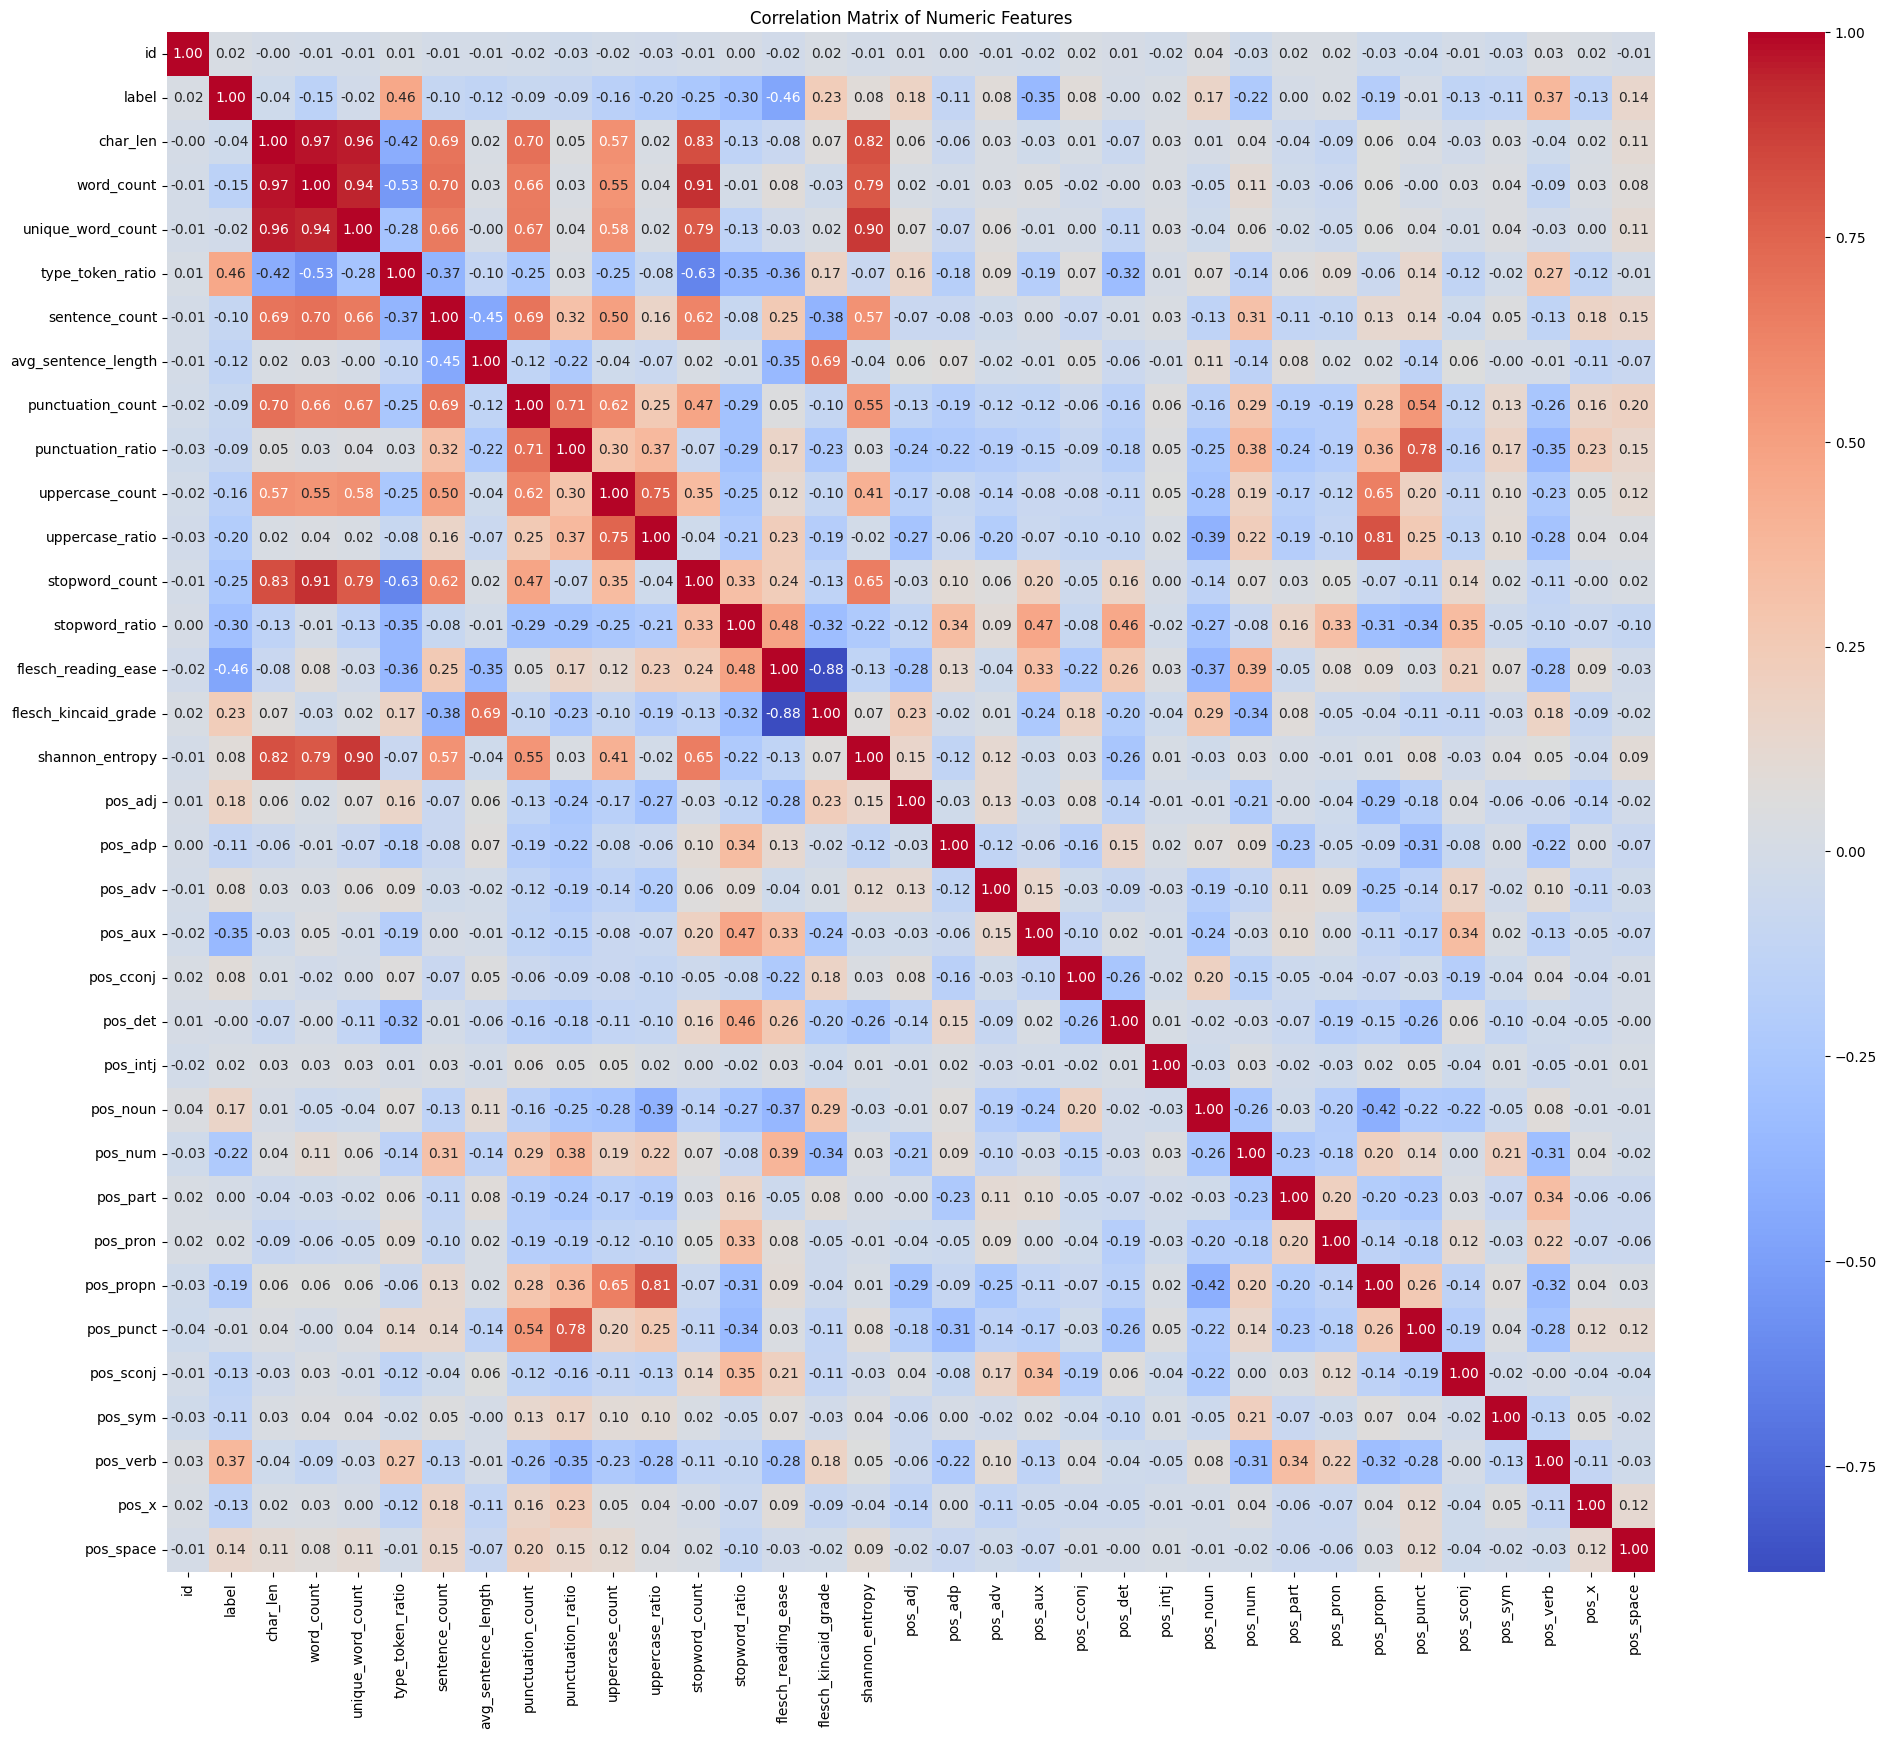

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns

train_w_struct = pd.read_csv(DATA_PATH + "train_w_struct.csv")

# Prepare structured data for correlation analysis
new_feat_train = train_w_struct.copy().drop(columns=['text'])
numeric_cols = new_feat_train.columns.tolist()
numeric_cols.remove('label')

# Plot correlation heatmap
corr = new_feat_train.corr()
plt.figure(figsize=(24,20))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Correlation Matrix of Numeric Features")
plt.show()

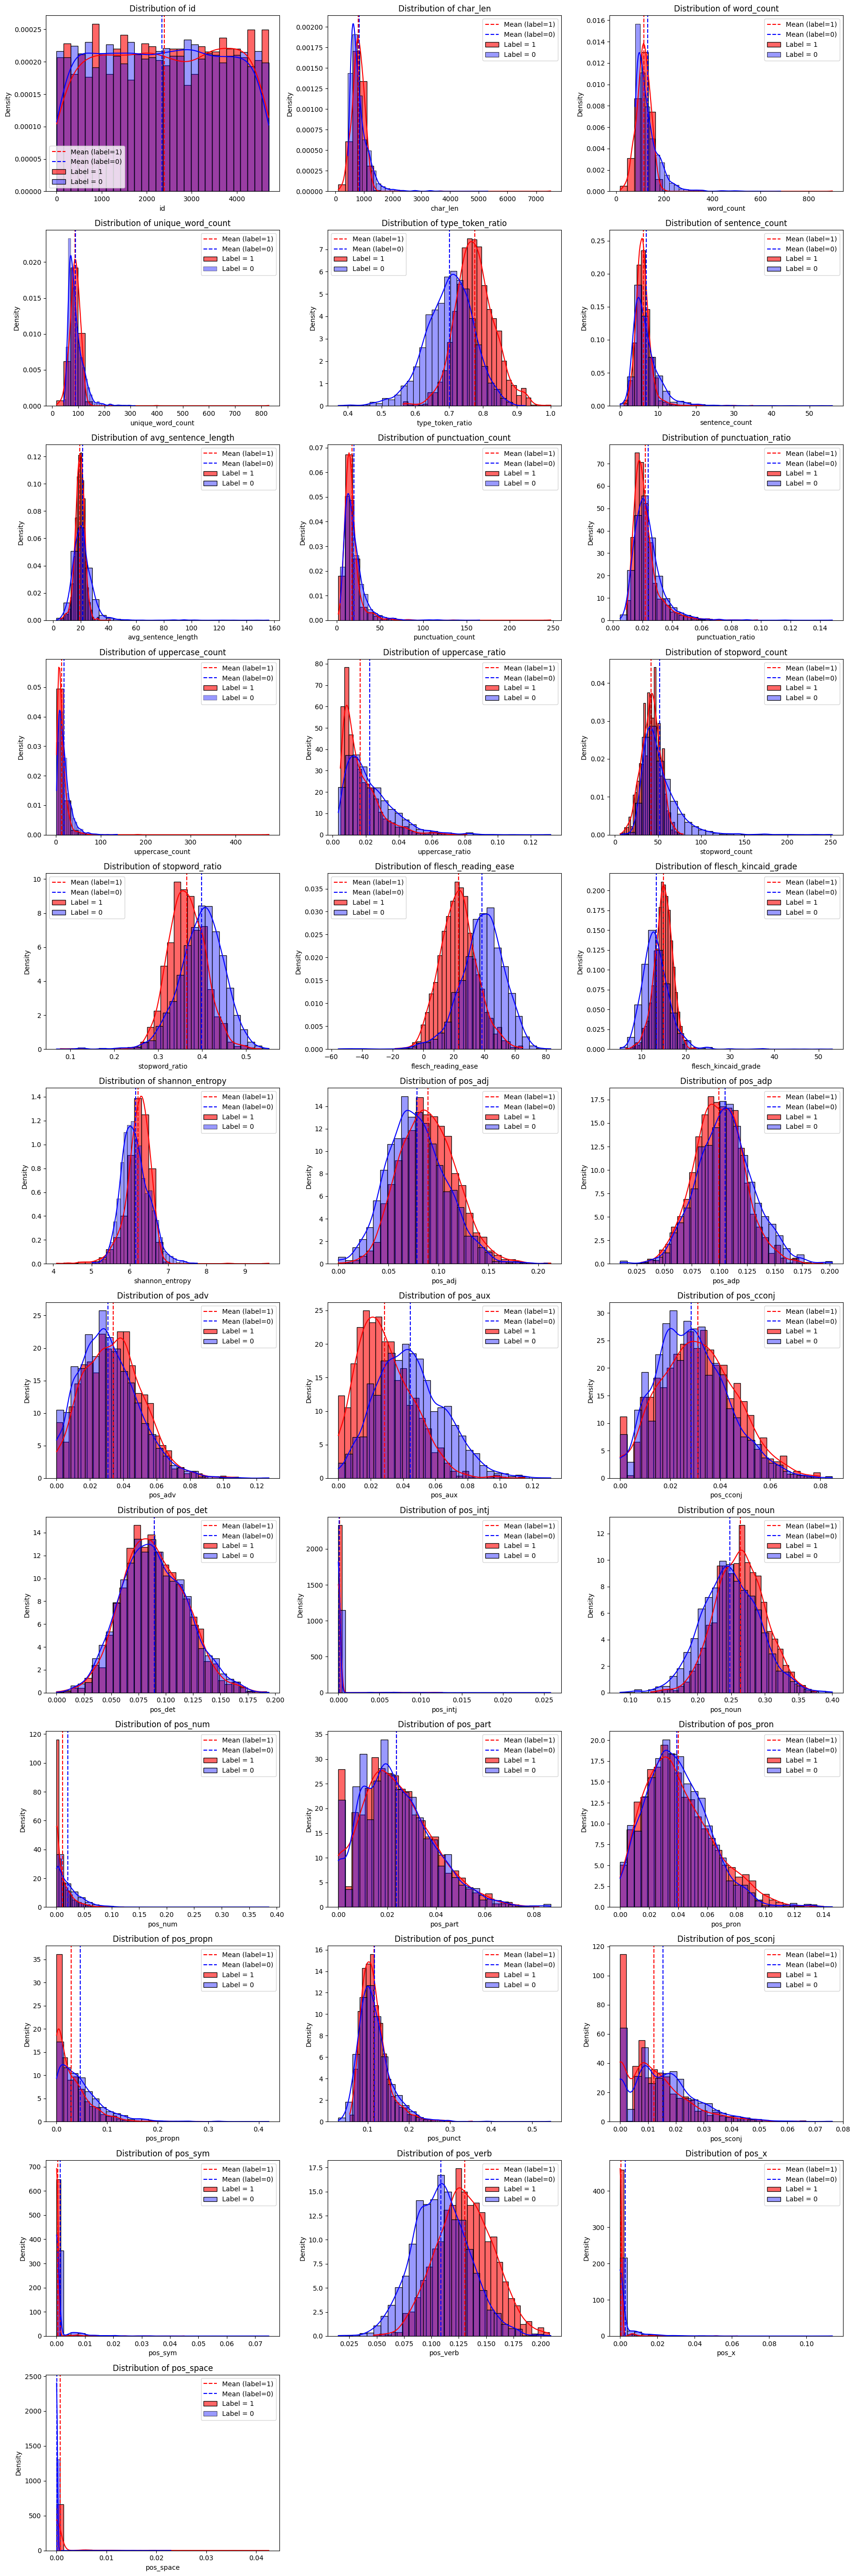

In [80]:
# Define grid size
n_cols = 3
n_rows = math.ceil(len(numeric_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    ax = axes[i]

    # Plot histograms
    sns.histplot(
        data=new_feat_train[new_feat_train['label'] == 1],
        x=col, bins=30, color='red', label='Label = 1',
        kde=True, stat='density', ax=ax, alpha=0.6
    )
    sns.histplot(
        data=new_feat_train[new_feat_train['label'] == 0],
        x=col, bins=30, color='blue', label='Label = 0',
        kde=True, stat='density', ax=ax, alpha=0.4
    )

    # Compute means
    mean_label1 = new_feat_train.loc[new_feat_train['label'] == 1, col].mean()
    mean_label0 = new_feat_train.loc[new_feat_train['label'] == 0, col].mean()

    # Add vertical mean lines (dotted)
    ax.axvline(mean_label1, color='red', linestyle='--', linewidth=1.5, label='Mean (label=1)')
    ax.axvline(mean_label0, color='blue', linestyle='--', linewidth=1.5, label='Mean (label=0)')

    ax.set_title(f"Distribution of {col}")
    ax.legend()

# Hide unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()